In [ ]:
!pip install pyarrow

In [27]:
import pyarrow.feather as feather
df = feather.read_feather("qsar.feather")

#inspecting dataframe

In [28]:
print(df)

      SpMax_L    J_Dz  nHM  F01  F04CN  NssssC  nCb    Cp  nCp  nO  ...  \
0       3.919  2.6909    0    0      0       0    0  31.4    2   0  ...   
1       4.170  2.1144    0    0      0       0    0  30.8    1   1  ...   
2       3.932  3.2512    0    0      0       0    0  26.7    2   4  ...   
3       3.000  2.7098    0    0      0       0    0  20.0    0   2  ...   
4       4.236  3.3944    0    0      0       0    0  29.4    2   4  ...   
...       ...     ...  ...  ...    ...     ...  ...   ...  ...  ..  ...   
1050    5.431  2.8955    0    0      0       2    0  32.1    4   1  ...   
1051    5.287  3.3732    0    0      9       0    0  35.3    0   9  ...   
1052    4.869  1.7670    0    1      9       0    5  44.4    0   4  ...   
1053    5.158  1.6914    2    0     36       0    9  56.1    0   0  ...   
1054    5.076  2.6588    2    0      0       0    4  54.5    0   0  ...   

      C_026  F02CN  nHDon  SpMax_Bm  Psi_i_A  nN   SM6_B  nArCOOR  nX  class  
0         0      0  

In [29]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


In [30]:
parameter_grid = {
    'learning_rate': [0.1, 0.01],
    'n_estimators': [10, 100],
    'max_depth': [1, 2, 3]
}


In [31]:
import numpy as np
import random

seed = 42
random.seed(seed)
np.random.seed(seed)

In [32]:
print(df.dtypes)

SpMax_L      float64
J_Dz         float64
nHM            int32
F01            int32
F04CN          int32
NssssC         int32
nCb            int32
Cp           float64
nCp            int32
nO             int32
F03CN          int32
SdssC        float64
HyWi_B       float64
LOC          float64
SM6_L        float64
F03C0          int32
Me           float64
Mi           float64
nN_N           int32
nArNO2         int32
nCRX3          int32
SpPosA_B     float64
nCIR           int32
B01C_Br        int32
B03C_Cl        int32
N_073          int32
SpMax_A      float64
Psi_i_1d     float64
B04CBr         int32
SdO          float64
TI2_L        float64
nCrt           int32
C_026          int32
F02CN          int32
nHDon          int32
SpMax_Bm     float64
Psi_i_A      float64
nN             int32
SM6_B        float64
nArCOOR        int32
nX             int32
class       category
dtype: object


In [33]:
from sklearn.model_selection import train_test_split

x = df.drop(columns='class')
y = df['class']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=seed)


In [34]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

gbm = GradientBoostingClassifier(random_state=seed)

In [46]:
from sklearn.model_selection import StratifiedKFold


cross_fold_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

gbm = GradientBoostingClassifier(loss='log_loss', random_state=seed)

In [47]:
grid_setting = GridSearchCV(
    estimator=gbm,
    param_grid=parameter_grid,
    cv=cross_fold_strategy,
    scoring='accuracy',
    n_jobs=2,
    verbose=3
)


In [48]:
grid_setting.fit(x_train, y_train)


Fitting 10 folds for each of 12 candidates, totalling 120 fits


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=42, shuffle=True),
             estimator=GradientBoostingClassifier(random_state=42), n_jobs=2,
             param_grid={'learning_rate': [0.1, 0.01], 'max_depth': [1, 2, 3],
                         'n_estimators': [10, 100]},
             scoring='accuracy', verbose=3)

In [49]:
print("The best parameters found are:", grid_setting.best_params_)
print("Best Cross validation accuracy:", grid_setting.best_score_)

The best parameters found are: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
Best Cross validation accuracy: 0.8657719363198815


In [52]:
print(grid_setting.cv_results_)

{'mean_fit_time': array([0.03276491, 0.27738922, 0.04926519, 0.45295861, 0.06834784,
       0.86355622, 0.03048918, 0.26963797, 0.04898567, 0.44565263,
       0.06699409, 0.64992347]), 'std_fit_time': array([0.00165158, 0.0053275 , 0.00343187, 0.00566773, 0.00419974,
       0.19707681, 0.00125675, 0.00653468, 0.00262643, 0.01065866,
       0.00301168, 0.01256225]), 'mean_score_time': array([0.00355282, 0.00391226, 0.00371158, 0.00371432, 0.00327199,
       0.00667672, 0.00324426, 0.00355895, 0.00318358, 0.00366976,
       0.00318286, 0.00422888]), 'std_score_time': array([0.00023455, 0.00054625, 0.00174089, 0.00013463, 0.00034243,
       0.00300206, 0.00026561, 0.00014919, 0.0001126 , 0.00013841,
       0.00016667, 0.00184447]), 'param_learning_rate': masked_array(data=[0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.01, 0.01, 0.01, 0.01,
                   0.01, 0.01],
             mask=[False, False, False, False, False, False, False, False,
                   False, False, False, False],
       fil

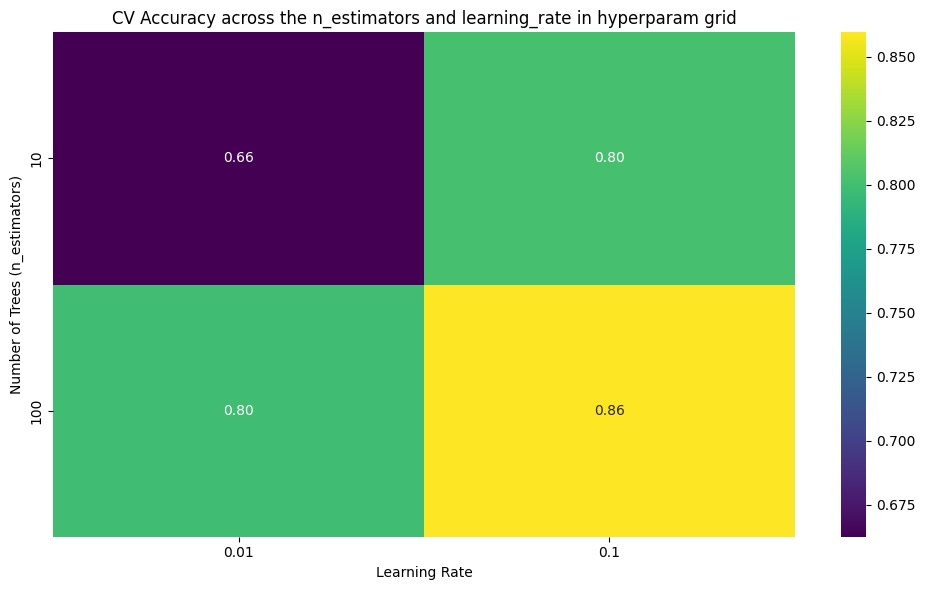

In [51]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

cross_validation_results = pd.DataFrame(grid_setting.cv_results_)
cross_validation_results = cross_validation_results.sort_values(by='mean_test_score', ascending=True)
cross_validation_results["learning_rate"] = cross_validation_results["param_learning_rate"].astype(float)
cross_validation_results["n_estimators"] = cross_validation_results["param_n_estimators"].astype(int)

heatmap_cv = cross_validation_results.pivot_table(
    values='mean_test_score',
    index='n_estimators',
    columns='learning_rate'
)

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_cv, annot=True, fmt=".2f", cmap="viridis")
plt.title("CV Accuracy across the n_estimators and learning_rate in hyperparam grid")
plt.xlabel("Learning Rate")
plt.ylabel("Number of Trees (n_estimators)")
plt.tight_layout()
plt.show()